**Checkpoint de 100 posições:** este experimento usa legacy/checkpoints/HardPos_/gpt_model_HardPos_.pt e 97 PS de histórico. Para o checkpoint de 10 posições solicitado, use HardPos_pares_cruzados_centro_contexto10.ipynb.

# PS central: saltos próximos e distantes nos dois sentidos

Selecionamos o PS com centro médio mais próximo de (0,5; 0,5) entre os observados ao menos dez vezes. Escolhemos destinos em seis distâncias e oito direções. Para cada PS periférico p, comparamos os pares **centro → p** e **p → centro**. Assim o mesmo deslocamento é testado com destinos diferentes e com destino central fixo. A entrada tem somente dois PS válidos, origem e destino. Primeiro testamos sem padding e depois nas posições finais de um contexto de 99, com padding mascarado no início. A atenção continua causal.

A distância entre os centros dos PS, dividida pelo intervalo mediano de 0,15 s, é uma pseudovelocidade ilustrativa. O modelo não recebe os centros nem o tempo. Uma ativação que cresce apenas quando o destino muda pode indicar localização; se cresce também no sentido inverso, há evidência mais forte de sensibilidade ao par origem–destino. Mesmo assim, saltos longos estão fora das transições observadas no treino.

In [1]:
%matplotlib inline
from pathlib import Path
import json, math, pickle
import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.nn import functional as F
from scipy.stats import spearmanr
import matplotlib.pyplot as plt
from IPython.display import display

root=Path('.')
df=pd.read_parquet(root/'bert_trainset_squared_25.gzip')
with (root/'ps_to_psid.pkl').open('rb') as f: mapping=pickle.load(f)
ids=df.position_state.map(mapping).to_numpy()
assert np.isfinite(ids).all()
ids=ids.astype(np.int64)
xy=np.stack(df.pos.to_numpy()).astype(float)
times=df.t.to_numpy(float)
centers=(pd.DataFrame({'ps_id':ids,'x':xy[:,0],'y':xy[:,1]})
         .groupby('ps_id',as_index=False).agg(x=('x','mean'),y=('y','mean'),visits=('x','size')))
centers['dist_to_middle']=np.hypot(centers.x-.5,centers.y-.5)
central=centers[centers.visits>=10].sort_values('dist_to_middle').iloc[0]
central_id=int(central.ps_id)
central_xy=central[['x','y']].to_numpy(float)
reference_dt=float(np.median(np.diff(times)))
center_array=np.full((ids.max()+1,2),np.nan)
center_array[centers.ps_id.to_numpy(int)]=centers[['x','y']].to_numpy(float)
real_step=np.linalg.norm(center_array[ids[1:]]-center_array[ids[:-1]],axis=1)
print('PS central:',central_id,'centro:',np.round(central_xy,4),'observações:',int(central.visits))
print('Maior passo real entre centros:',round(float(real_step.max()),4),'| intervalo de referência:',round(reference_dt,3),'s')
from project_support.csv_runs import notebook_csv_path


PS central: 137 centro: [0.5193 0.4841] observações: 10
Maior passo real entre centros: 0.129 | intervalo de referência: 0.15 s


Desvio radial máximo: 0.0349


,min,median,max
ring,,,
0,0.016,0.036,0.063
1,0.068,0.080,0.089
2,0.147,0.159,0.163
3,0.263,0.275,0.295
4,0.383,0.403,0.415
5,0.445,0.476,0.487


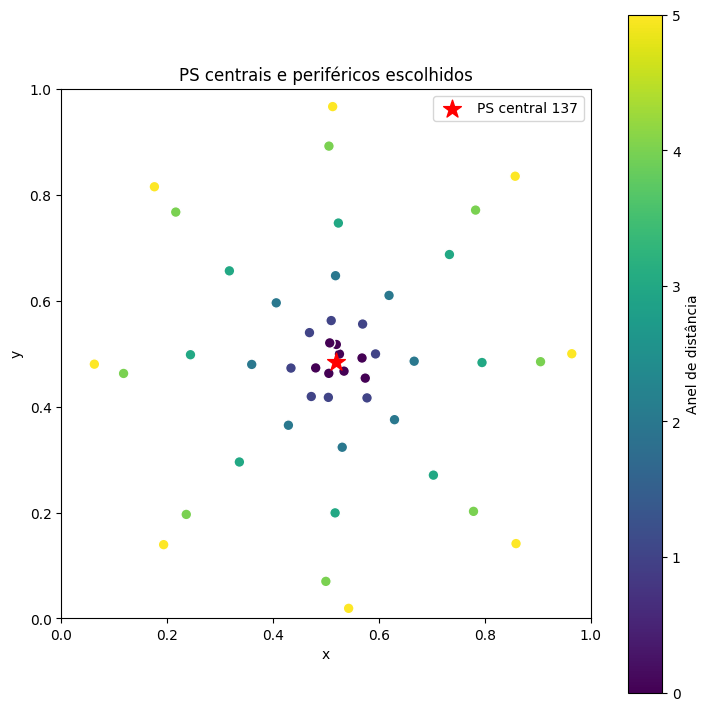

In [2]:
radii=[.03,.08,.16,.28,.40,.48]
sector_count=8
pool=centers[centers.ps_id!=central_id].copy()
pool_xy=pool[['x','y']].to_numpy(float)
pool_ids=pool.ps_id.to_numpy(int)
used=set()
chosen=[]
for ring_id,radius in enumerate(radii):
    for sector in range(sector_count):
        angle=2*np.pi*sector/sector_count
        desired=central_xy+radius*np.array([np.cos(angle),np.sin(angle)])
        error=np.linalg.norm(pool_xy-desired,axis=1)
        ranking=np.argsort(error)
        index=next(int(i) for i in ranking if int(pool_ids[i]) not in used)
        ps_id=int(pool_ids[index]); used.add(ps_id)
        actual_radius=float(np.linalg.norm(pool_xy[index]-central_xy))
        chosen.append((ring_id,sector,radius,ps_id,float(pool_xy[index,0]),float(pool_xy[index,1]),actual_radius))
chosen=pd.DataFrame(chosen,columns=['ring','sector','target_radius','peripheral_ps_id','x','y','distance'])
assert chosen.peripheral_ps_id.nunique()==len(chosen)==len(radii)*sector_count
print('Desvio radial máximo:',round(float((chosen.distance-chosen.target_radius).abs().max()),4))
display(chosen.groupby('ring').distance.agg(['min','median','max']).round(3))

records=[]; pairs=[]
for row in chosen.itertuples(index=False):
    for direction,source,dest in [('centro_para_fora',central_id,row.peripheral_ps_id),
                                  ('fora_para_centro',row.peripheral_ps_id,central_id)]:
        pairs.append([source,dest])
        records.append((row.ring,row.sector,row.target_radius,row.peripheral_ps_id,
                        direction,source,dest,row.distance,row.distance/reference_dt))
inputs=torch.tensor(pairs,dtype=torch.long)
meta=pd.DataFrame(records,columns=['ring','sector','target_radius','peripheral_ps_id',
                                   'direction','source_ps_id','dest_ps_id','distance','pseudo_speed'])
assert inputs.shape==(len(radii)*sector_count*2,2)
assert (meta.loc[meta.direction=='fora_para_centro','dest_ps_id']==central_id).all()
fig,ax=plt.subplots(figsize=(7,7),constrained_layout=True)
scatter=ax.scatter(chosen.x,chosen.y,c=chosen.ring,cmap='viridis',s=60,edgecolor='white')
ax.scatter([central_xy[0]],[central_xy[1]],c='red',s=180,marker='*',label=f'PS central {central_id}')
ax.set(xlim=(0,1),ylim=(0,1),xlabel='x',ylabel='y',title='PS centrais e periféricos escolhidos')
ax.set_aspect('equal'); ax.legend()
fig.colorbar(scatter,ax=ax,label='Anel de distância')
(root/'imgs').mkdir(exist_ok=True)
fig.savefig(root/'imgs/hardpos_pares_centro_mapa.png',dpi=150,bbox_inches='tight')
display(fig)
plt.close(fig)

In [3]:
training_nb=json.loads((root/'navitran_vizz_reboot_gpt_squared_25_span.ipynb').read_text(encoding='utf-8'))
for cell_no in (21,23): exec(''.join(training_nb['cells'][cell_no]['source']),globals())
pad_id=int(ids.max())+1
model=TrajectoryBERT_HardPos(pad_id+1,embed_size=16,num_layers=1,num_heads=1,
                             hidden_dim=32,dropout=.2,pad_token_id=pad_id,max_len=100,causal=True)
model.load_state_dict(torch.load(root/'legacy/checkpoints/HardPos_/gpt_model_HardPos_.pt',map_location='cpu',weights_only=True))
model.eval()
torch.set_num_threads(min(4,torch.get_num_threads()))
layer=model.encoder.layers[0]

@torch.inference_mode()
def extract(batch):
    emb=model.embedding(batch)
    pos=model.position_embedding(emb)
    q,k,v=F.linear(pos,layer.self_attn.in_proj_weight,layer.self_attn.in_proj_bias).chunk(3,-1)
    attn,_=layer.self_attn(pos,pos,pos,attn_mask=model._causal_mask(batch.shape[1],batch.device),need_weights=False)
    residual=pos+layer.dropout1(attn)
    norm1=layer.norm1(residual)
    ff1=layer.linear1(norm1)
    ff_act=layer.activation(ff1)
    ff2=layer.linear2(layer.dropout(ff_act))
    encoder=layer.norm2(norm1+layer.dropout2(ff2))
    representations={'token_embedding':emb,'attention_output':attn,
                     'attention_norm':norm1,'ff_activation':ff_act,'encoder_output':encoder}
    probabilities=torch.softmax(model.fc_out(encoder[:,0]),dim=-1).gather(1,batch[:,1:2]).squeeze(1)
    return {name:a[:,1].numpy() for name,a in representations.items()},probabilities.numpy(),encoder

blocks={}; probability=[]
for offset in range(0,len(inputs),32):
    batch=inputs[offset:offset+32]
    reps,p,encoder=extract(batch)
    if offset==0:
        with torch.inference_mode():
            direct=model(batch)
            torch.testing.assert_close(model.fc_out(encoder[:,-1]),direct[:,-1],atol=1e-5,rtol=1e-5)
            direct_p=torch.softmax(direct[:,0],dim=-1).gather(1,batch[:,1:2]).squeeze(1)
            torch.testing.assert_close(torch.from_numpy(p),direct_p,atol=1e-6,rtol=1e-6)
    probability.append(p)
    for name,a in reps.items(): blocks.setdefault(name,[]).append(a)
features={}
for name,chunks in blocks.items():
    matrix=np.concatenate(chunks)
    for j in range(matrix.shape[1]): features[f'{name}__d{j:02d}']=matrix[:,j]
results=pd.concat([meta,pd.DataFrame(features)],axis=1)
results['p_destination_given_source']=np.concatenate(probability)
results['surprisal_nats']=-np.log(results.p_destination_given_source.clip(lower=1e-30))
results.to_parquet(root/'legacy/analysis/HardPos_pares_cruzados_centro.parquet',index=False)
print('Pares:',len(results),'| dimensões internas:',len(features))

Pares: 96 | dimensões internas: 96


/home/mgteus/workspace/navitrans/.nav/lib/python3.10/site-packages/torch/nn/modules/transformer.py:307: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.self_attn.num_heads is odd
  warnings.warn(f"enable_nested_tensor is True, but self.use_nested_tensor is False because {why_not_sparsity_fast_path}")


## Mesmos dois PS nas posições finais do contexto de treino

O primeiro teste usa dois tokens nas posições 0 e 1. Para verificar a sensibilidade à posição absoluta, repetimos os mesmos pares nas posições 97 e 98, equivalentes a 97 tokens de padding no início com máscara de atenção. Não há outros PS no input. Como o encoder possui uma camada, calcular apenas os dois tokens válidos nessas posições produz a mesma ativação final que o modelo com padding inicial; verificamos essa equivalência numericamente.

In [4]:
results_pos01=results.copy()

@torch.inference_mode()
def extract_at_end_positions(batch):
    emb=model.embedding(batch)
    pos=emb+model.position_embedding.pe[97:99].unsqueeze(0)
    q,k,v=F.linear(pos,layer.self_attn.in_proj_weight,layer.self_attn.in_proj_bias).chunk(3,-1)
    attn,_=layer.self_attn(pos,pos,pos,attn_mask=model._causal_mask(2,batch.device),need_weights=False)
    norm1=layer.norm1(pos+layer.dropout1(attn))
    ff_act=layer.activation(layer.linear1(norm1))
    encoder=layer.norm2(norm1+layer.dropout2(layer.linear2(layer.dropout(ff_act))))
    reps={'token_embedding':emb,'attention_output':attn,
          'attention_norm':norm1,'ff_activation':ff_act,'encoder_output':encoder}
    p=torch.softmax(model.fc_out(encoder[:,0]),dim=-1).gather(1,batch[:,1:2]).squeeze(1)
    return {name:a[:,1].numpy() for name,a in reps.items()},p.numpy(),encoder

new_blocks={}; new_probs=[]
for offset in range(0,len(inputs),32):
    pair=inputs[offset:offset+32]
    reps,p,encoder=extract_at_end_positions(pair)
    if offset==0:
        padded=torch.full((len(pair),99),pad_id,dtype=torch.long)
        padded[:,-2:]=pair
        attention_mask=(padded!=pad_id).long()
        with torch.inference_mode():
            direct=model(padded,attention_mask=attention_mask)
            torch.testing.assert_close(model.fc_out(encoder[:,-1]),direct[:,-1],atol=1e-5,rtol=1e-5)
            p_direct=torch.softmax(direct[:,-2],dim=-1).gather(1,pair[:,1:2]).squeeze(1)
            torch.testing.assert_close(torch.from_numpy(p),p_direct,atol=1e-6,rtol=1e-6)
    new_probs.append(p)
    for name,a in reps.items(): new_blocks.setdefault(name,[]).append(a)
new_features={}
for name,chunks in new_blocks.items():
    matrix=np.concatenate(chunks)
    for j in range(matrix.shape[1]): new_features[f'{name}__d{j:02d}']=matrix[:,j]
results=pd.concat([meta,pd.DataFrame(new_features)],axis=1)
results['p_destination_given_source']=np.concatenate(new_probs)
results['surprisal_nats']=-np.log(results.p_destination_given_source.clip(lower=1e-30))
results.to_parquet(root/'legacy/analysis/HardPos_pares_cruzados_centro_leftpad.parquet',index=False)
print('Equivalência com padding inicial confirmada; pares:',len(results))
print('ff_activation__d06 ativa no teste sem padding:',int((results_pos01['ff_activation__d06']>0).sum()),
      'e nas posições finais:',int((results['ff_activation__d06']>0).sum()))

Equivalência com padding inicial confirmada; pares: 96
ff_activation__d06 ativa no teste sem padding: 4 e nas posições finais: 3


## O modelo reconhece a diferença de distância?

A probabilidade do destino é calculada após ver apenas o PS de origem. Um salto improvável no sentido centro → fora pode continuar improvável no sentido inverso. A ativação de uma dimensão, porém, pode responder diferentemente aos dois sentidos. O embedding do token final funciona como controle: no sentido fora → centro, ele é idêntico em todos os pares, porque o último PS está fixo.

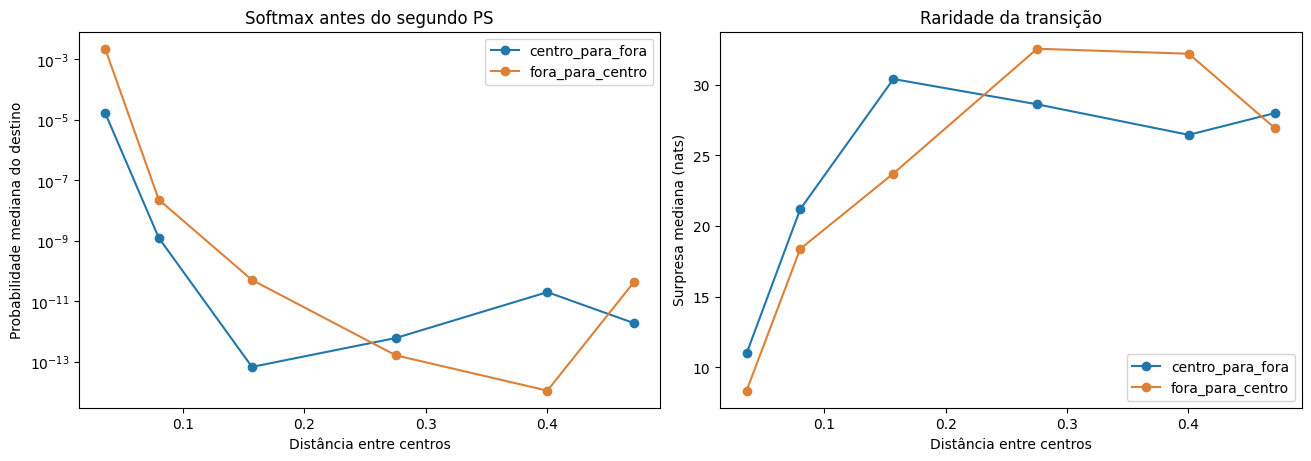

distance  pseudo_speed  p_destination_given_source
direction        ring                                                    
centro_para_fora 0      0.03575       0.23833                     0.00002
                 1      0.07964       0.53091                     0.00000
                 2      0.15947       1.06313                     0.00000
                 3      0.27548       1.83651                     0.00000
                 4      0.40296       2.68643                     0.00000
                 5      0.47576       3.17175                     0.00000
fora_para_centro 0      0.03575       0.23833                     0.00224
                 1      0.07964       0.53091                     0.00000
                 2      0.15947       1.06313                     0.00000
                 3      0.27548       1.83651                     0.00000
                 4      0.40296       2.68643                     0.00000
                 5      0.47576       3.17175                     0.00000

In [5]:
order=['centro_para_fora','fora_para_centro']
fig,axes=plt.subplots(1,2,figsize=(13,4.5),constrained_layout=True)
for direction,color in zip(order,['#2277aa','#dc8137']):
    part=results[results.direction==direction]
    grouped=part.groupby('ring').agg(distance=('distance','mean'),
                                     probability=('p_destination_given_source','median'),
                                     surprise=('surprisal_nats','median'))
    axes[0].plot(grouped.distance,grouped.probability,marker='o',color=color,label=direction)
    axes[1].plot(grouped.distance,grouped.surprise,marker='o',color=color,label=direction)
axes[0].set_yscale('log')
axes[0].set(xlabel='Distância entre centros',ylabel='Probabilidade mediana do destino',title='Softmax antes do segundo PS')
axes[1].set(xlabel='Distância entre centros',ylabel='Surpresa mediana (nats)',title='Raridade da transição')
for ax in axes: ax.legend()
fig.savefig(root/'imgs/hardpos_pares_centro_softmax.png',dpi=150,bbox_inches='tight')
display(fig)
plt.close(fig)
display(results.groupby(['direction','ring'])[['distance','pseudo_speed','p_destination_given_source']].median().round(5))

## Ativações em ambos os sentidos

Calculamos a correlação de Spearman de cada dimensão com a distância nos dois sentidos. Para uma resposta compartilhada, exigimos o mesmo sinal nas duas correlações. Metade dos setores angulares seleciona a candidata; a outra metade verifica se a relação se repete em direções não usadas na escolha. Também mostramos a unidade ff_activation__d06, que respondeu aos saltos extremos no experimento anterior.

Unidades escolhidas: ['ff_activation__d06', 'ff_activation__d14', 'encoder_output__d03']


direction                        centro_para_fora  fora_para_centro
feature             sectors                                        
encoder_output__d03 selecao                 0.436             0.230
                    todos                   0.362             0.091
                    verificacao             0.359            -0.130
ff_activation__d06  selecao                 0.179               NaN
                    todos                   0.123               NaN
                    verificacao               NaN               NaN
ff_activation__d14  selecao                -0.180            -0.262
                    todos                  -0.258            -0.174
                    verificacao            -0.344            -0.015

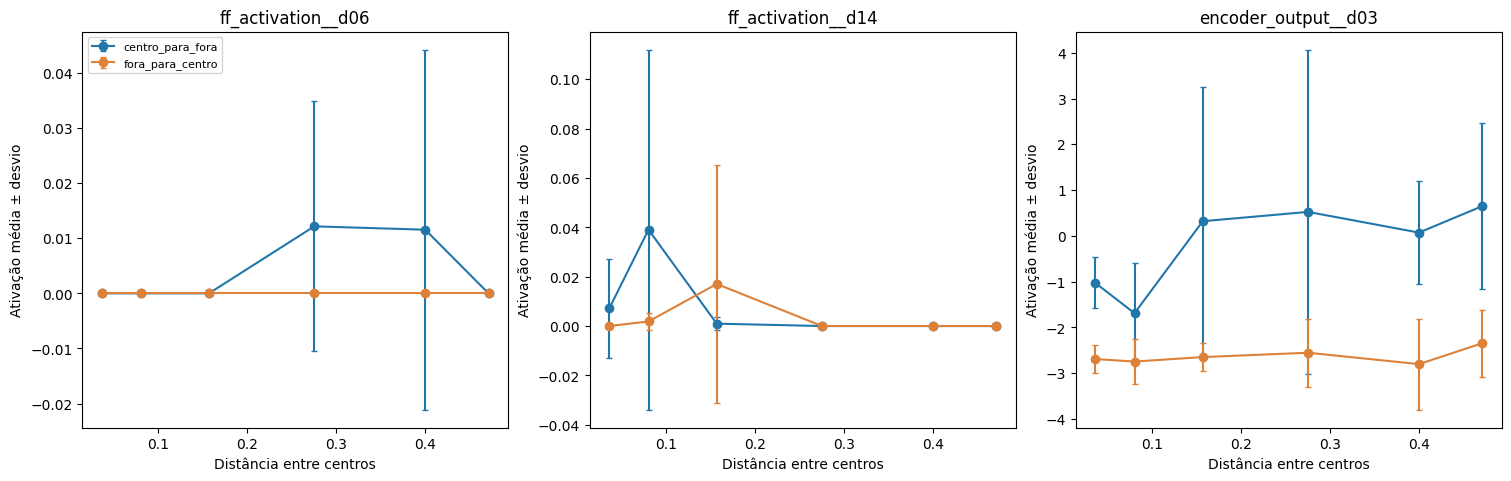

In [6]:
feature_cols=list(features)
rows=[]
for feature in feature_cols:
    for sector_set,sectors in [('selecao',[0,2,4,6]),('verificacao',[1,3,5,7]),('todos',list(range(8)))]:
        for direction in order:
            part=results[(results.direction==direction)&(results.sector.isin(sectors))]
            a=part[feature].to_numpy(float)
            rho=float(spearmanr(part.distance,a).statistic) if np.std(a)>1e-10 else np.nan
            rows.append((feature,feature.rsplit('__d',1)[0],sector_set,direction,rho))
scores=pd.DataFrame(rows,columns=['feature','stage','sectors','direction','rho'])
scores.to_csv(notebook_csv_path('HardPos_pares_cruzados_centro', 'HardPos_pares_cruzados_scores.csv'),index=False)
selection=scores[scores.sectors=='selecao'].pivot(index=['feature','stage'],columns='direction',values='rho').reset_index()
a=selection.centro_para_fora.to_numpy(float)
b=selection.fora_para_centro.to_numpy(float)
selection['shared_score']=np.where(np.sign(a)==np.sign(b),np.minimum(np.abs(a),np.abs(b)),0)
selection['shared_score']=selection.shared_score.fillna(0)
ff_best=(selection[selection.stage=='ff_activation'].sort_values('shared_score',ascending=False).iloc[0].feature)
encoder_best=(selection[selection.stage=='encoder_output'].sort_values('shared_score',ascending=False).iloc[0].feature)
shown=list(dict.fromkeys(['ff_activation__d06',ff_best,encoder_best]))
print('Unidades escolhidas:',shown)
display(scores[scores.feature.isin(shown)].pivot(index=['feature','sectors'],columns='direction',values='rho').round(3))

fig,axes=plt.subplots(1,len(shown),figsize=(5*len(shown),4.7),constrained_layout=True)
axes=np.atleast_1d(axes)
for ax,feature in zip(axes,shown):
    for direction,color in zip(order,['#2277aa','#dc8137']):
        part=results[results.direction==direction]
        grouped=part.groupby('ring').agg(distance=('distance','mean'),activation=(feature,'mean'),
                                         variation=(feature,'std'))
        ax.errorbar(grouped.distance,grouped.activation,yerr=grouped.variation,
                    marker='o',capsize=2,color=color,label=direction)
    ax.set(xlabel='Distância entre centros',ylabel='Ativação média ± desvio',title=feature)
axes[0].legend(fontsize=8)
fig.savefig(root/'imgs/hardpos_pares_centro_ativacoes.png',dpi=150,bbox_inches='tight')
display(fig)
plt.close(fig)

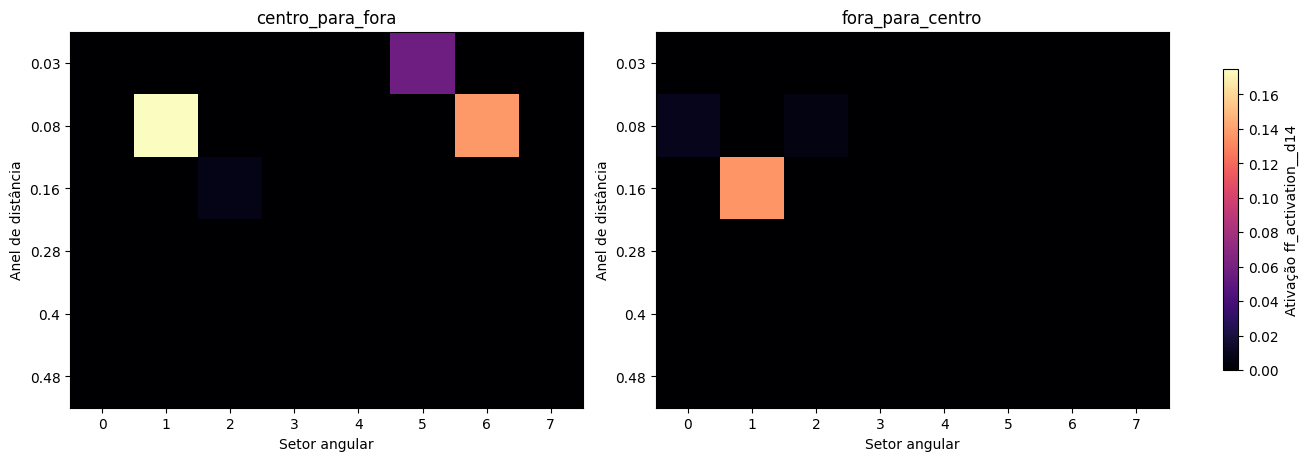

ff_activation__d06 verificação: centro_para_fora rho=+nan, fora_para_centro rho=+nan
ff_activation__d14 verificação: centro_para_fora rho=-0.344, fora_para_centro rho=-0.015
encoder_output__d03 verificação: centro_para_fora rho=+0.359, fora_para_centro rho=-0.130


In [7]:
# Mapa de ativação por distância e direção para a unidade do feedforward selecionada.
unit=ff_best
fig,axes=plt.subplots(1,2,figsize=(13,4.5),constrained_layout=True)
for ax,direction in zip(axes,order):
    part=results[results.direction==direction]
    matrix=part.pivot(index='ring',columns='sector',values=unit).to_numpy(float)
    im=ax.imshow(matrix,aspect='auto',cmap='magma',vmin=0,vmax=max(results[unit].max(),1e-6))
    ax.set(xlabel='Setor angular',ylabel='Anel de distância',title=direction)
    ax.set_xticks(range(8)); ax.set_yticks(range(len(radii)),[str(r) for r in radii])
fig.colorbar(im,ax=axes,label='Ativação '+unit,shrink=.8)
fig.savefig(root/'imgs/hardpos_pares_centro_unidade_mapa.png',dpi=150,bbox_inches='tight')
display(fig)
plt.close(fig)

# Avaliação direta: a resposta da unidade anterior em ambos os sentidos.
for feature in shown:
    part=scores[(scores.feature==feature)&(scores.sectors=='verificacao')]
    print(feature,'verificação:',', '.join(f'{row.direction} rho={row.rho:+.3f}' for row in part.itertuples()))

## Repetição com histórico real de 97 PS

Os pares isolados têm comprimento muito menor que a entrada usada no treino. Repetimos o experimento nas ocorrências reais do PS central: preservamos os 97 PS anteriores e variamos apenas os dois tokens finais entre centro → periférico e periférico → centro. Todos os contextos continuam causais. No sentido inverso, o penúltimo PS sintético pode criar também uma transição inédita com o token anterior do histórico; interpretamos esse braço com cautela.

Ocorrências reais do PS central: 10 | contextos sintéticos: 960


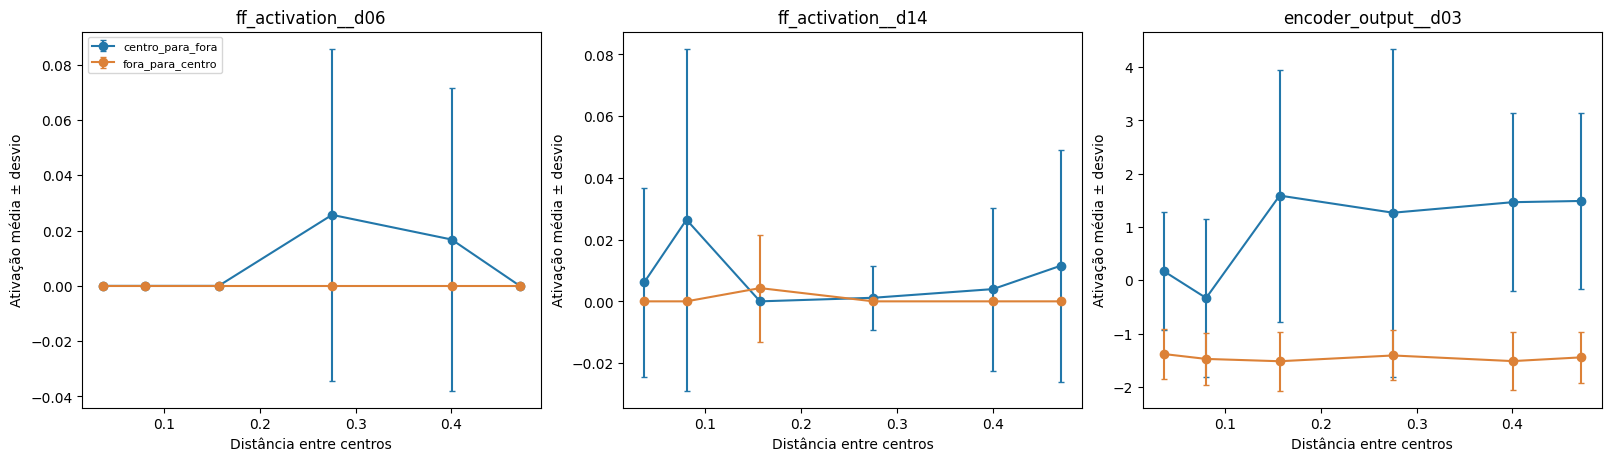

centro_para_fora ff d06 ativou em 0.05 das variantes com histórico real
fora_para_centro ff d06 ativou em 0.0 das variantes com histórico real


In [8]:
central_times=np.flatnonzero(ids==central_id)
central_times=central_times[central_times>=97]
split_boundary=int(.8*len(ids))
central_times=np.array([t for t in central_times if t<split_boundary or t-97>=split_boundary],dtype=int)
full_inputs=[]; full_rows=[]
for t in central_times:
    prefix=ids[t-97:t]
    assert len(prefix)==97
    part='treino' if t<split_boundary else 'teste'
    for row in chosen.itertuples(index=False):
        for direction,source,dest in [('centro_para_fora',central_id,row.peripheral_ps_id),
                                      ('fora_para_centro',row.peripheral_ps_id,central_id)]:
            full_inputs.append(np.r_[prefix,source,dest])
            full_rows.append((int(t),part,row.ring,row.sector,row.peripheral_ps_id,
                              direction,row.distance,source,dest))
full_inputs=torch.tensor(np.stack(full_inputs),dtype=torch.long)
full_meta=pd.DataFrame(full_rows,columns=['central_t','split','ring','sector','peripheral_ps_id',
                                          'direction','distance','source_ps_id','dest_ps_id'])
assert full_inputs.shape[1]==99
print('Ocorrências reais do PS central:',len(central_times),'| contextos sintéticos:',len(full_inputs))

@torch.inference_mode()
def extract_full(batch):
    emb=model.embedding(batch)
    pos=model.position_embedding(emb)
    attn,_=layer.self_attn(pos,pos,pos,attn_mask=model._causal_mask(99,batch.device),need_weights=False)
    norm1=layer.norm1(pos+layer.dropout1(attn))
    ff_act=layer.activation(layer.linear1(norm1))
    encoder=layer.norm2(norm1+layer.dropout2(layer.linear2(layer.dropout(ff_act))))
    return {'ff_activation__d06':ff_act[:,-1,6].numpy(),
            'ff_activation__d14':ff_act[:,-1,14].numpy(),
            'encoder_output__d03':encoder[:,-1,3].numpy()},encoder
full_blocks={}
for offset in range(0,len(full_inputs),24):
    batch=full_inputs[offset:offset+24]
    values,encoder=extract_full(batch)
    if offset==0:
        with torch.inference_mode():
            torch.testing.assert_close(model.fc_out(encoder[:,-1]),model(batch)[:,-1],atol=1e-5,rtol=1e-5)
    for name,a in values.items(): full_blocks.setdefault(name,[]).append(a)
full_results=full_meta.copy()
for name,chunks in full_blocks.items(): full_results[name]=np.concatenate(chunks)
full_results.to_parquet(root/'legacy/analysis/HardPos_pares_cruzados_centro_contexto_real.parquet',index=False)

fig,axes=plt.subplots(1,3,figsize=(16,4.5),constrained_layout=True)
for ax,feature in zip(axes,['ff_activation__d06','ff_activation__d14','encoder_output__d03']):
    for direction,color in zip(order,['#2277aa','#dc8137']):
        part=full_results[full_results.direction==direction]
        grouped=part.groupby('ring').agg(distance=('distance','mean'),activation=(feature,'mean'),
                                         spread=(feature,'std'))
        ax.errorbar(grouped.distance,grouped.activation,yerr=grouped.spread,
                    marker='o',capsize=2,color=color,label=direction)
    ax.set(xlabel='Distância entre centros',ylabel='Ativação média ± desvio',title=feature)
axes[0].legend(fontsize=8)
fig.savefig(root/'imgs/hardpos_pares_centro_contexto_real.png',dpi=150,bbox_inches='tight')
display(fig)
plt.close(fig)
for direction in order:
    part=full_results[full_results.direction==direction]
    print(direction,'ff d06 ativou em',round(float((part['ff_activation__d06']>0).mean()),3),
          'das variantes com histórico real')

## Interpretação

Se a mesma unidade variar com a distância ao manter o destino central fixo, sua resposta não pode ser explicada apenas pelo embedding do PS final. Para chamar essa resposta de velocidade, ainda é preciso mostrar relação com deslocamento por unidade de tempo em trajetórias realistas e intervalos conhecidos. Os pares distantes deste notebook testam uma intervenção fora das transições habituais e podem ativar respostas a entradas improváveis.

O teste com histórico real permite observar se a resposta dos pares isolados muda quando o modelo recebe a escala de contexto usada no treino.